# Classification de la Qualité du Vin
**Projet Machine Learning 1 — EFREI (2026-2027)**  
**Auteur :** Anissa Brignone, Perrine Grelet  

---


Import des bibliothèques

In [ ]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)
import warnings
warnings.filterwarnings('ignore')

Import des données

In [ ]:
# fetch dataset 
df = fetch_ucirepo(id=186) 

# data (as pandas dataframes) 
X = df.data.features.copy() 
y = df.data.targets 
  
# metadata 
print(df.metadata) 
  
# variable information 
print(df.variables) 


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [ ]:
if 'color' in df.data.original.columns:
    color_series = df.data.original['color']
    X['is_red'] = (color_series == 'red').astype(int)

In [ ]:
print(X.shape, y.shape)

(6497, 12) (6497, 1)


In [ ]:
X.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,0.246114
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.430779
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,0.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,0.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,0.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,0.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,1.000000


In [ ]:
print("Valeurs manquantes par colonne :")
print(X.isna().sum())

Valeurs manquantes par colonne :
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
is_red                  0
dtype: int64


6497 Vins et 0 données manquantes dans les différentes colonnes.

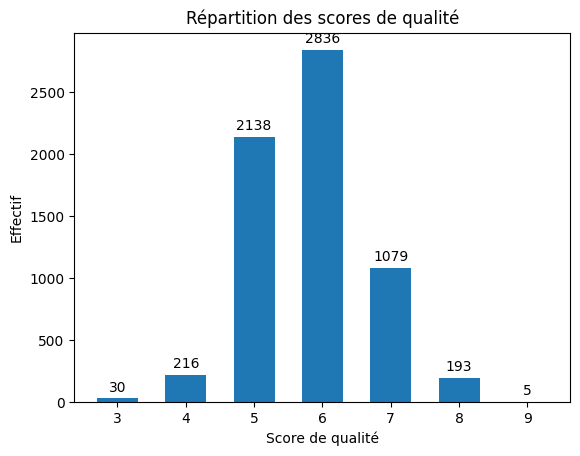

In [ ]:
counts = y['quality'].value_counts().sort_index()

bars = plt.bar(counts.index, counts.values, width=0.6)
plt.bar_label(bars, padding=3)
plt.xlabel('Score de qualité')
plt.ylabel('Effectif')
plt.title('Répartition des scores de qualité')
plt.show()

La grande majorité des échantillons se concentre sur les notes 5 et 6 (environ 76,6 % du jeu de données). À l'inverse, les notes extrêmes sont très rares : les vins de faible qualité et de haute qualité constituent une faible minorité et parfois même absents. Ce fort déséquilibre de classe devra être pris en compte lors de l'entraînement des modèles de classification.

Transformation en classification binaire : un vin est considéré comme bon si sa qualité est supérieure ou égale à 7.

In [ ]:
y_bin = (y['quality'] >= 7).astype(int)

Équilibre des classes après binarisation

              effectif  pourcentage (%)
quality                                
Mauvais (<7)      5220             80.3
Bon (>=7)         1277             19.7


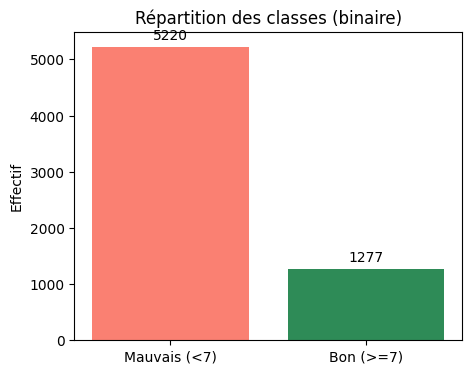

In [ ]:
counts = y_bin.value_counts().sort_index()
pct = (y_bin.value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({'effectif': counts, 'pourcentage (%)': pct}).rename(
    index={0: 'Mauvais (<7)', 1: 'Bon (>=7)'}))
 
plt.figure(figsize=(5, 4))
bars = plt.bar(['Mauvais (<7)', 'Bon (>=7)'], counts.values, color=['salmon', 'seagreen'])
plt.bar_label(bars, padding=3)
plt.ylabel('Effectif')
plt.title('Répartition des classes (binaire)')
plt.show()

Le jeu de données est déséquilibré, on observe qu'il y a environ 80 % de mauvais vins pour 20 % de bons vin. Il faudra donc juger les modèles avec le F1-score, le rappel et l'AUC plutôt qu'avec l'accuracy seule, et utiliser class_weight='balanced' quand c'est possible.

Histogrammes des variables

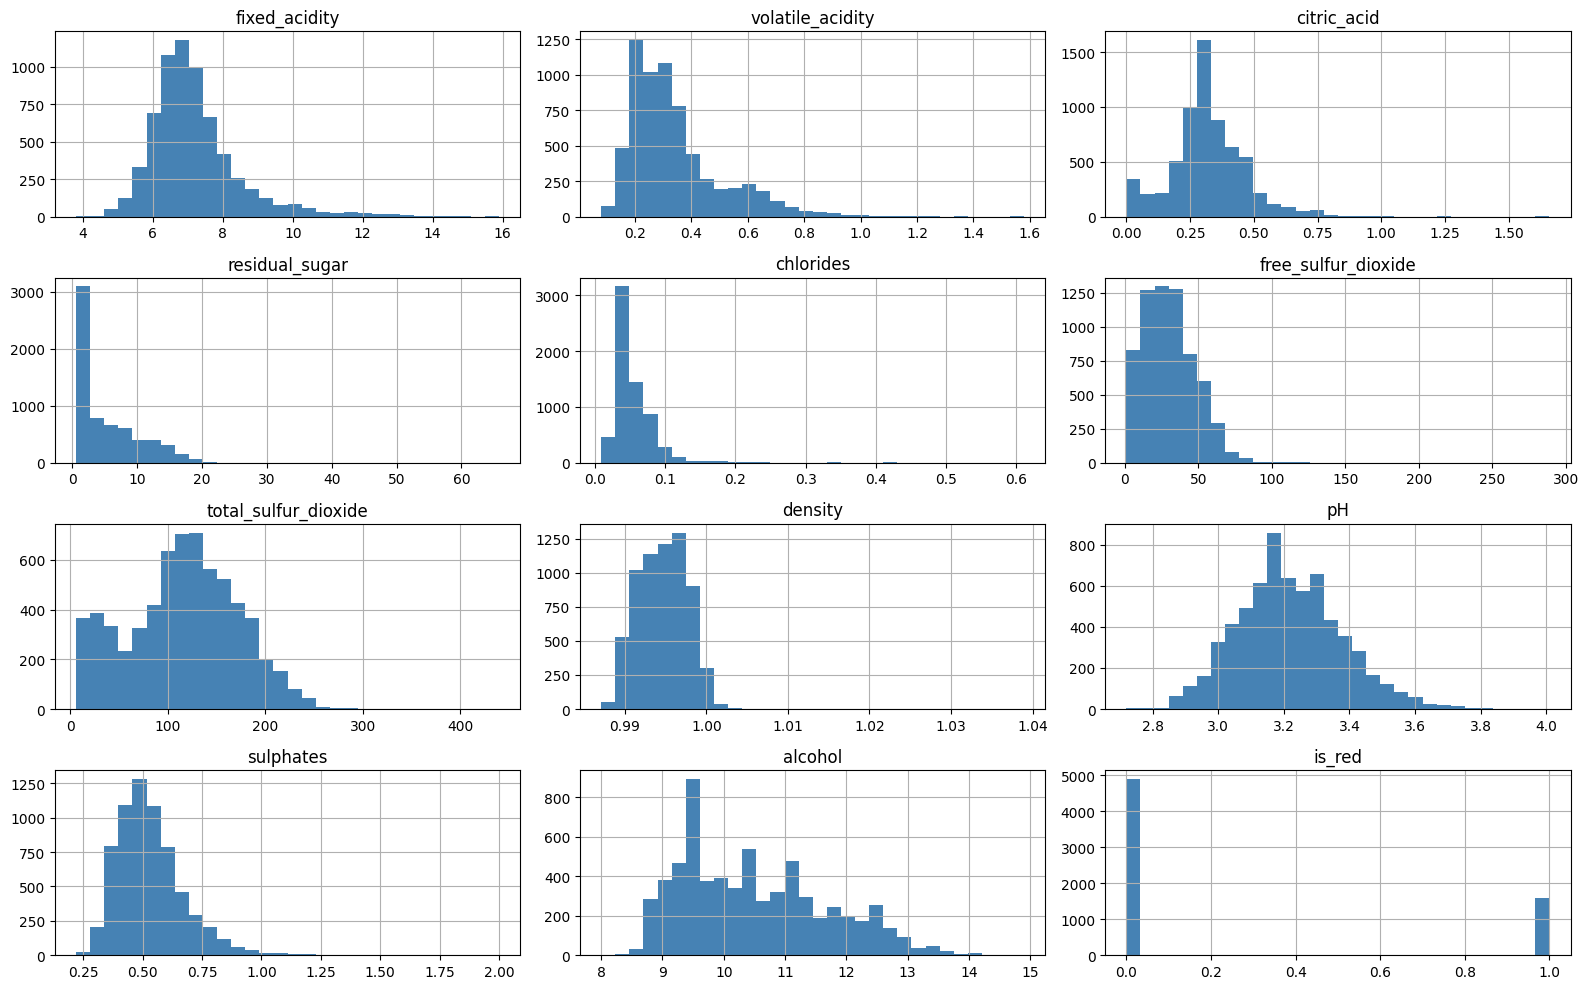

chlorides               5.40
sulphates               1.80
fixed_acidity           1.72
volatile_acidity        1.50
residual_sugar          1.44
free_sulfur_dioxide     1.22
is_red                  1.18
alcohol                 0.57
density                 0.50
citric_acid             0.47
pH                      0.39
total_sulfur_dioxide   -0.00
dtype: float64


In [ ]:
X.hist(bins=30, figsize=(16, 10), color='steelblue')
plt.tight_layout()
plt.show()

# Asymétrie : plus elle est éloignée de 0, plus la distribution est déséquilibrée
print(X.skew().round(2).sort_values(ascending=False))

Plusieurs variables ont une distribution fortement asymétrique à droite. À l'inverse, pH, density et alcohol sont peu asymétriques, et is_red est une variable binaire.

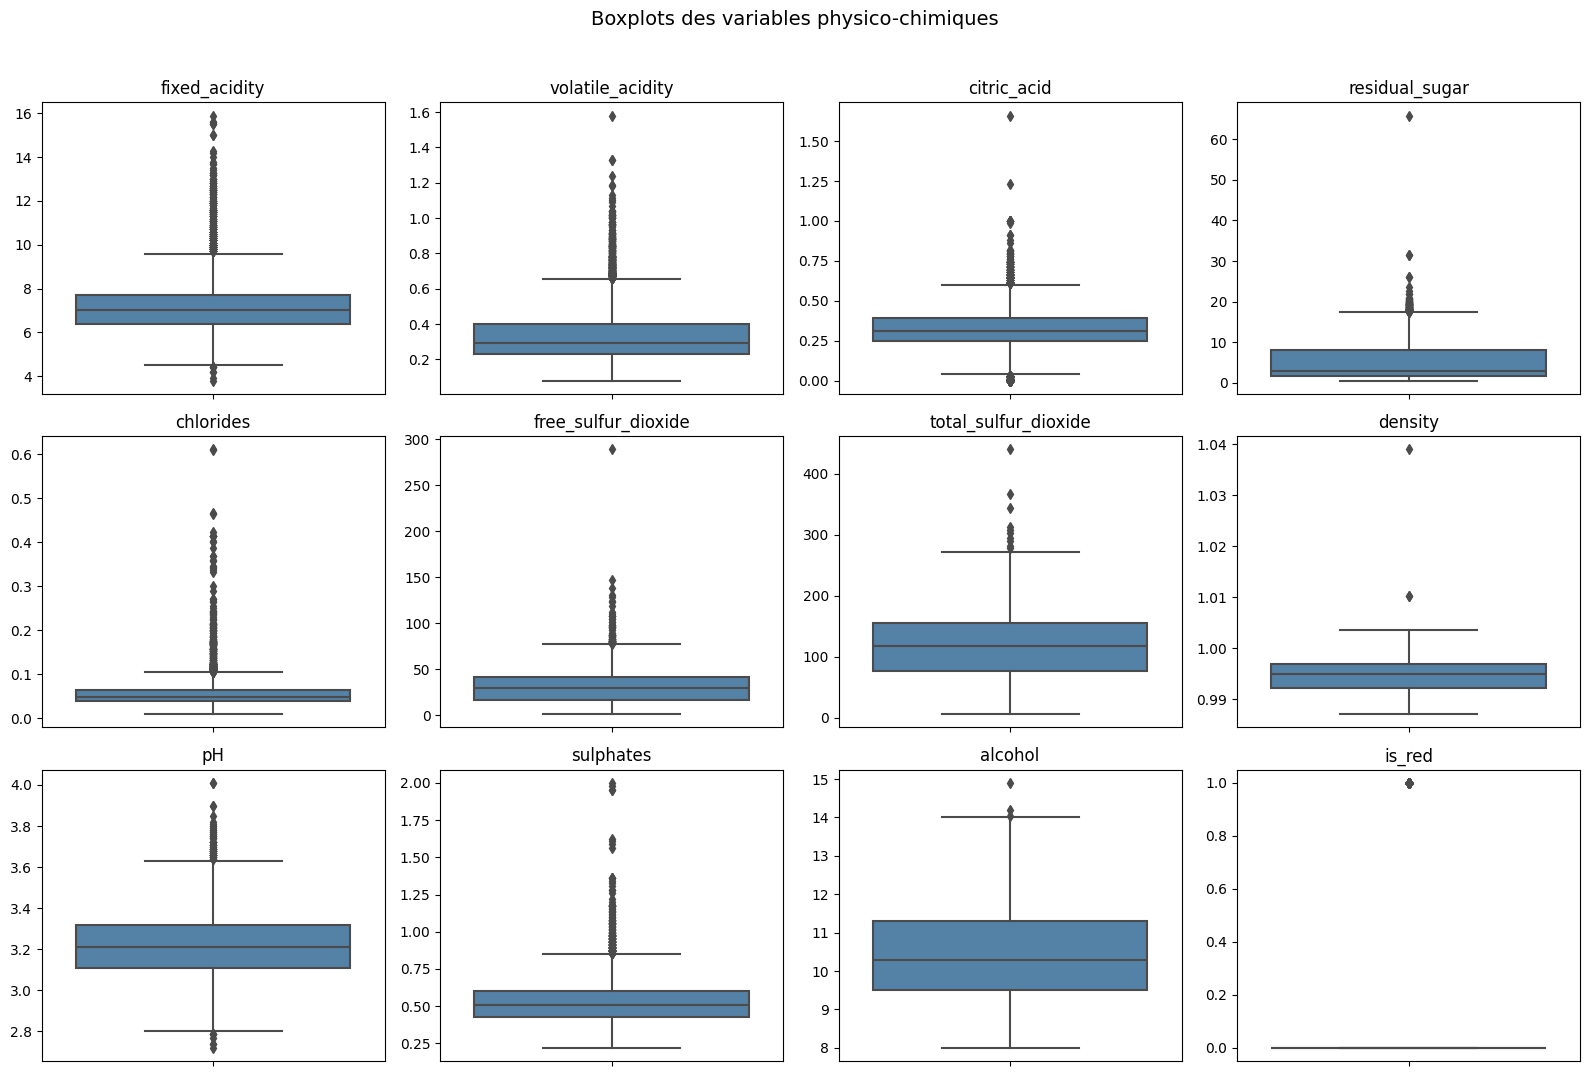

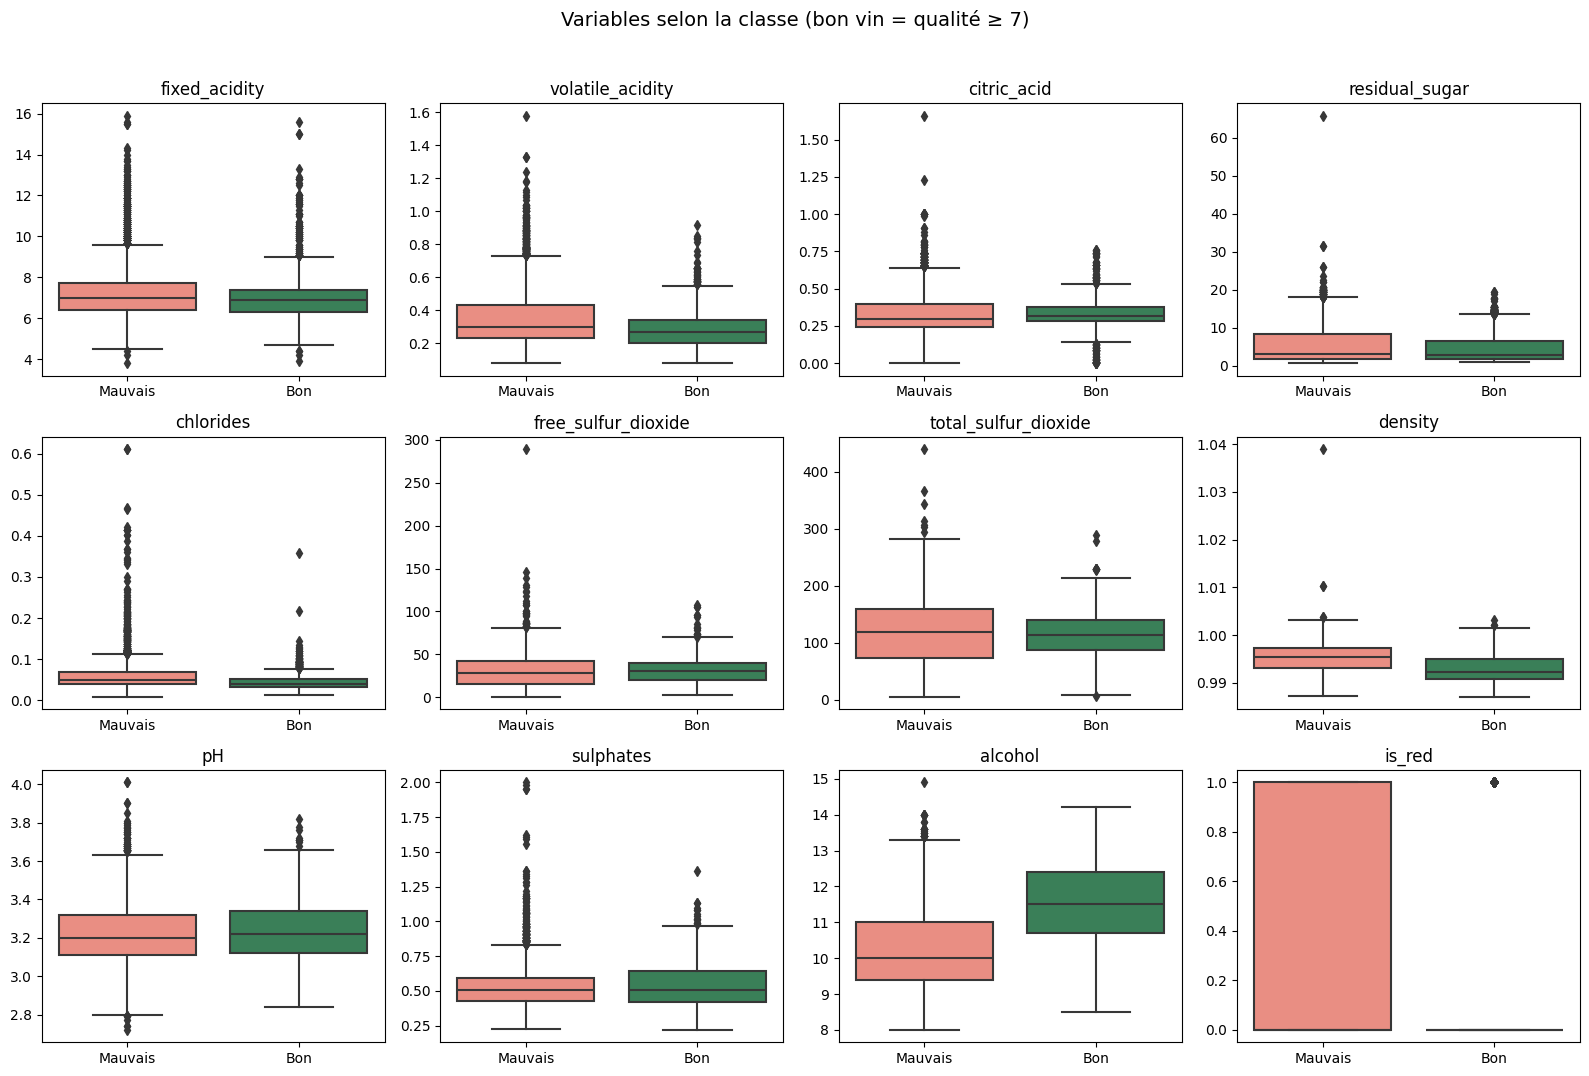

In [ ]:
# Boxplot de chaque variable 
cols = X.columns
n_cols = 4
n_rows = int(np.ceil(len(cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(y=X[col], ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_ylabel('')
for ax in axes.flat[len(cols):]:      # cache les cases vides
    ax.set_visible(False)
plt.suptitle("Boxplots des variables physico-chimiques", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# Boxplot de chaque variable selon (mauvais / bon vin)
data = X.copy()
data['bon_vin'] = y_bin.values

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(x='bon_vin', y=col, data=data, ax=ax, palette=['salmon', 'seagreen'])
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(['Mauvais', 'Bon'])
for ax in axes.flat[len(cols):]:
    ax.set_visible(False)
plt.suptitle("Variables selon la classe (bon vin = qualité ≥ 7)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


On remarque beaucoup de valeurs aberrantes, notamment pour l'acide citrique et l'acidité volatile. Lorsque l'on regarde selon la classe, les bons vins (qualité supérieure ou égale à 7) présentent une médiane nettement supérieure. Ils se distinguent également par une acidité volatile et une densité plus faibles. 

Les boxplots révèlent de nombreuses valeurs extrêmes. Elles peuvent être des mesures plausibles et non des erreurs, et les supprimer risquerait d'appauvrir la classe minoritaire des bons vins. Nous les conservons donc et utilisons un RobustScaler, qui limite leur influence sur la mise à l'échelle, ce qui profite aux modèles sensibles aux distances (k-NN, SVM) et à la régression logistique. Nous comparerons ce choix au StandardScaler en validation croisée.

Corrélation de chaque variable avec la qualité

density                -0.306
volatile_acidity       -0.266
chlorides              -0.201
is_red                 -0.119
fixed_acidity          -0.077
total_sulfur_dioxide   -0.041
residual_sugar         -0.037
pH                      0.020
sulphates               0.038
free_sulfur_dioxide     0.055
citric_acid             0.086
alcohol                 0.444
dtype: float64


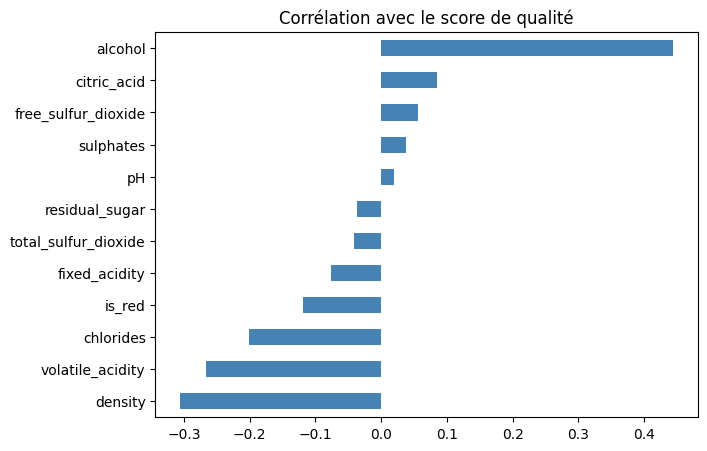

In [ ]:
corr_cible = X.corrwith(y['quality']).sort_values()
print(corr_cible.round(3))

corr_cible.plot(kind='barh', figsize=(7, 5), color='steelblue')
plt.title("Corrélation avec le score de qualité")
plt.show()

L'alcool est de loin la variable la plus corrélée à la qualité (0,44), suivi de la densité (-0,31), de l'acidité volatile (-0,27) et des chlorures (-0,20). Toutes les autres variables ont une corrélation inférieure à 0,12 en valeur absolue. Les liens linéaires avec la cible sont donc faibles à modérés, ce qui laisse prévoir des performances modestes.

In [ ]:
correlation_matrix = X.corr(numeric_only=True).round(2)
correlation_matrix

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red
fixed_acidity,1.00,0.22,0.32,-0.11,0.30,-0.28,-0.33,0.46,-0.25,0.30,-0.10,0.49
volatile_acidity,0.22,1.00,-0.38,-0.20,0.38,-0.35,-0.41,0.27,0.26,0.23,-0.04,0.65
citric_acid,0.32,-0.38,1.00,0.14,0.04,0.13,0.20,0.10,-0.33,0.06,-0.01,-0.19
residual_sugar,-0.11,-0.20,0.14,1.00,-0.13,0.40,0.50,0.55,-0.27,-0.19,-0.36,-0.35
chlorides,0.30,0.38,0.04,-0.13,1.00,-0.20,-0.28,0.36,0.04,0.40,-0.26,0.51
free_sulfur_dioxide,-0.28,-0.35,0.13,0.40,-0.20,1.00,0.72,0.03,-0.15,-0.19,-0.18,-0.47
total_sulfur_dioxide,-0.33,-0.41,0.20,0.50,-0.28,0.72,1.00,0.03,-0.24,-0.28,-0.27,-0.70
density,0.46,0.27,0.10,0.55,0.36,0.03,0.03,1.00,0.01,0.26,-0.69,0.39
pH,-0.25,0.26,-0.33,-0.27,0.04,-0.15,-0.24,0.01,1.00,0.19,0.12,0.33
sulphates,0.30,0.23,0.06,-0.19,0.40,-0.19,-0.28,0.26,0.19,1.00,-0.00,0.49


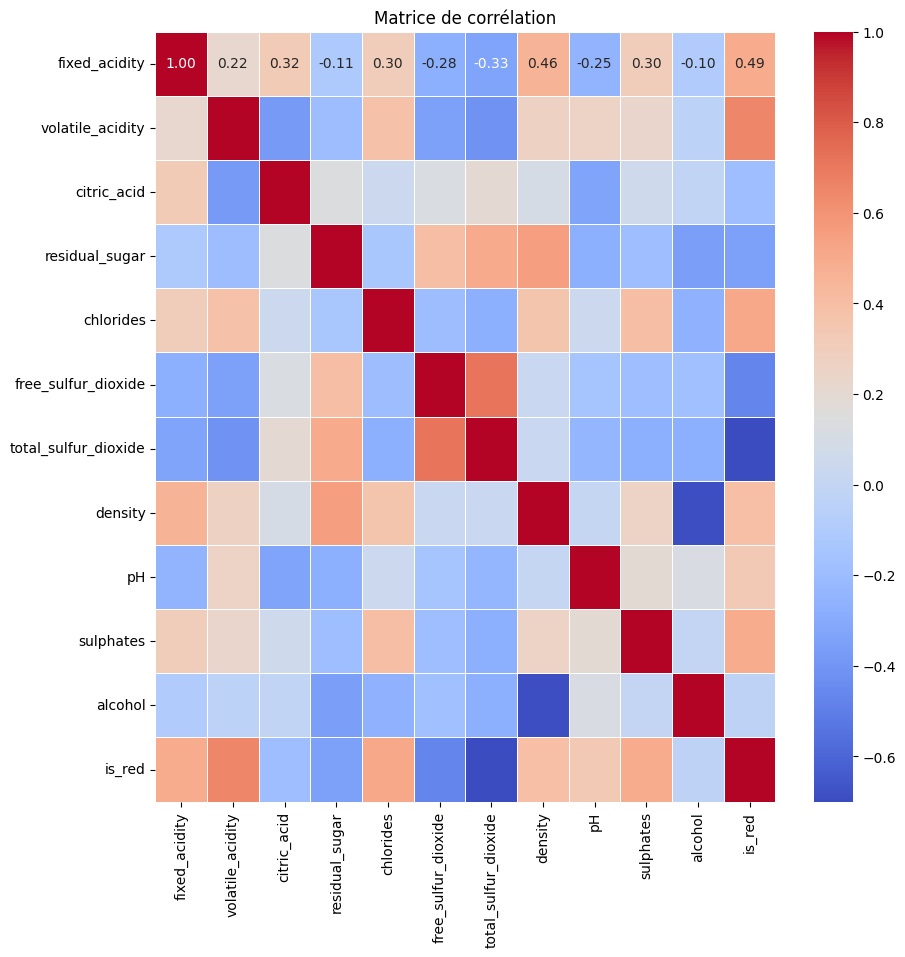

In [ ]:
plt.figure(figsize=(10, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matrice de corrélation")
plt.show()

On observe une forte multicolinéarité entre plusieurs caractéristiques du vin. La relation la plus marquée concerne free_sulfur_dioxide et total_sulfur_dioxide, fortement corrélés à 0,72. Density présente également des corrélations avec le taux d'alcool (-0,69), le sucre résiduel (0,55) et l'acidité fixe (0,46).

Nous allons faire l'ACP pour voir si nous pouvons réduire le nombre de variables à mettre dans le modèle et ainsi le simplifier. 

Nombre de composantes pour conserver 90% de la variance : 8


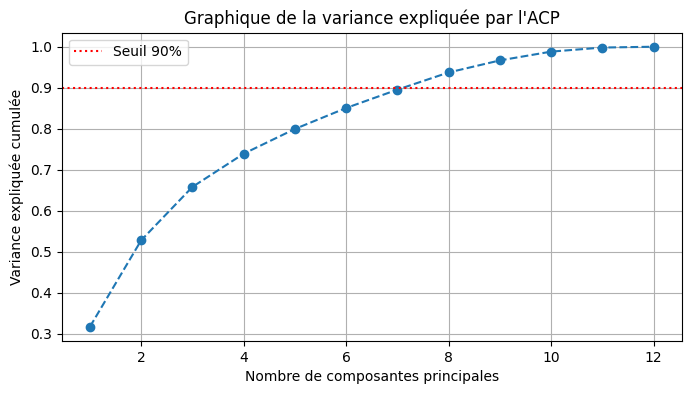

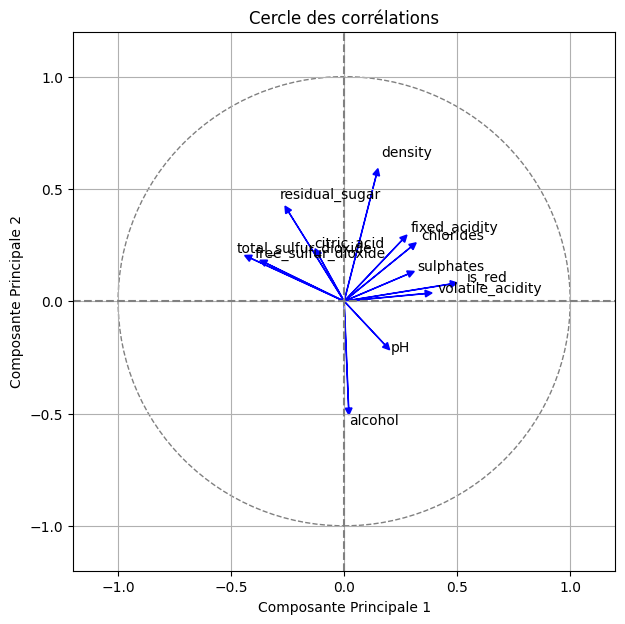

In [ ]:

# Normalisation des données 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Application de l'ACP
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Variance expliquée et cumulée
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# Affichage du nombre de composantes à garder (ex: pour 90% de variance)
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"Nombre de composantes pour conserver 90% de la variance : {n_components_90}")

# Graphique du coude (Variance expliquée cumulée)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle=':', label='Seuil 90%')
plt.xlabel('Nombre de composantes principales')
plt.ylabel('Variance expliquée cumulée')
plt.title('Graphique de la variance expliquée par l\'ACP')
plt.legend()
plt.grid(True)
plt.show()

# Cercle des corrélations (sur les 2 premières composantes)
fig, ax = plt.subplots(figsize=(7, 7))
for i, feature in enumerate(X.columns):
    ax.arrow(0, 0, pca.components_[0, i], pca.components_[1, i], 
             head_width=0.03, head_length=0.03, fc='blue', ec='blue')
    ax.text(pca.components_[0, i] * 1.15, pca.components_[1, i] * 1.15, feature, color='black')

circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--')
ax.add_patch(circle)
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.axhline(0, color='grey', linestyle='--')
plt.axvline(0, color='grey', linestyle='--')
plt.xlabel('Composante Principale 1')
plt.ylabel('Composante Principale 2')
plt.title('Cercle des corrélations')
plt.grid(True)
plt.show()

L'analyse de la matrice de corrélation du jeu de données met en évidence d'importantes redondances entre les variables physico-chimiques. La relation la plus marquée concerne le dioxyde de soufre libre (free_sulfur_dioxide) et total (total_sulfur_dioxide), fortement corrélés à 0,72. On observe également une forte corrélation négative entre la densité (density) et le taux d'alcool (-0,69), ainsi qu'un lien positif fort entre la densité et le sucre résiduel (0,55). Ces fortes interdépendances confirment la présence de multicolinéarité et justifient une étape de réduction de dimension via l'ACP afin d'optimiser les performances des modèles de classification.

Gestion des doublons. Le jeu de données contient des lignes strictement identiques (mêmes mesures et même note). Si on les garde, un même vin peut se retrouver à la fois dans le train et dans le test : les modèles qui mémorisent (k-NN, arbre de décision) obtiennent alors des scores trop beaux. Pour le vérifier, on entraîne un k-NN avec puis sans doublons.

In [ ]:
# Les doublons sont les lignes identiques 
donnees = X.copy()
donnees['quality'] = y['quality']
doublons = donnees.duplicated()
print("Nombre de doublons :", doublons.sum(), ":", round(doublons.mean() * 100, 1), "%")

# Test k-NN avec et sans doublons
for nom, X_test_dup, y_test_dup in [("avec doublons", X, y_bin),
                                    ("sans doublons", X[~doublons], y_bin[~doublons])]:
    Xa, Xb, ya, yb = train_test_split(X_test_dup, y_test_dup, test_size=0.2,
                                      stratify=y_test_dup, random_state=42)
    knn_test = Pipeline([('scaler', RobustScaler()),
                         ('model', KNeighborsClassifier(n_neighbors=5, weights='distance'))])
    knn_test.fit(Xa, ya)
    print("k-NN", nom, ": F1 =", round(f1_score(yb, knn_test.predict(Xb)), 3))

Nombre de doublons : 1177 soit 18.1 %
k-NN avec doublons : F1 = 0.642
k-NN sans doublons : F1 = 0.529


Le jeu de données contient 1177 doublons (18,1 %). Leur présence gonfle les scores : le F1 du k-NN passe de 0,642 avec doublons à 0,529 sans doublons, car le modèle retrouve dans le train des vins identiques à ceux du test. Nous supprimons donc les doublons avant la séparation train/test. Il reste 5320 vins, dont 19,0 % de bons vins.

Suppression des doublons, puis séparation en train (80 %) et test (20 %). On sépare avant toute mise à l'échelle ou sélection de variables, pour que le jeu de test reste totalement inconnu des modèles. L'option stratify garde la même proportion de bons vins dans les deux jeux.

In [ ]:
X_clean = X[~doublons]
y_clean = y_bin[~doublons]

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, stratify=y_clean, random_state=42)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Bons vins dans le train :", round(y_train.mean() * 100, 1), "%")
print("Bons vins dans le test :", round(y_test.mean() * 100, 1), "%")

Train : (4256, 12) | Test : (1064, 12)
Bons vins dans le train : 19.0 %
Bons vins dans le test : 19.0 %


Sélection de variables, uniquement sur le jeu d'entraînement. On utilise trois méthodes : la corrélation de chaque variable avec la cible, les coefficients de la régression logistique et l'importance des variables d'un Random Forest.

In [ ]:
# Normalisation du train (sur le train uniquement)
ss = StandardScaler()
X_train_norm = ss.fit_transform(X_train)

# Corrélation de chaque variable avec la cible
corr_train = X_train.corrwith(y_train)

# données normalisées : on peut comparer les coefficients de la régression logistique entre eux
logreg = LogisticRegression(class_weight='balanced', max_iter=1000)
logreg.fit(X_train_norm, y_train)

# Importance des variables dans un Random Forest
rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

selection = pd.DataFrame({
    'Correlation': corr_train,
    'Coef_reg_logistique': logreg.coef_[0],
    'Importance_RF': rf.feature_importances_
}, index=X_train.columns)

print(selection.round(3).sort_values('Importance_RF', ascending=False))

                      Correlation  Coef_reg_logistique  Importance_RF
alcohol                     0.423                0.617          0.201
density                    -0.298               -1.375          0.119
chlorides                  -0.159               -0.206          0.091
volatile_acidity           -0.143               -0.622          0.088
total_sulfur_dioxide       -0.074               -0.425          0.085
citric_acid                 0.058                0.008          0.076
sulphates                   0.038                0.382          0.071
residual_sugar             -0.086                0.984          0.068
free_sulfur_dioxide         0.005                0.284          0.068
pH                          0.042                0.525          0.067
fixed_acidity              -0.043                0.783          0.063
is_red                     -0.081                0.185          0.003


On va mesurer l'influence de chaque variable sur le résultat : 
- la **corrélation** indique la force de la relation linéaire directe (-1 à 1)
- les **coefficients de régression logistique** traduisent l'impact positif ou négatif d'une variable sur la probabilité calculée par le modèle
- l'**importance Random Forest** quantifie le poids global de chaque variable dans la précision des arbres de décision, indépendamment du sens de son effet.

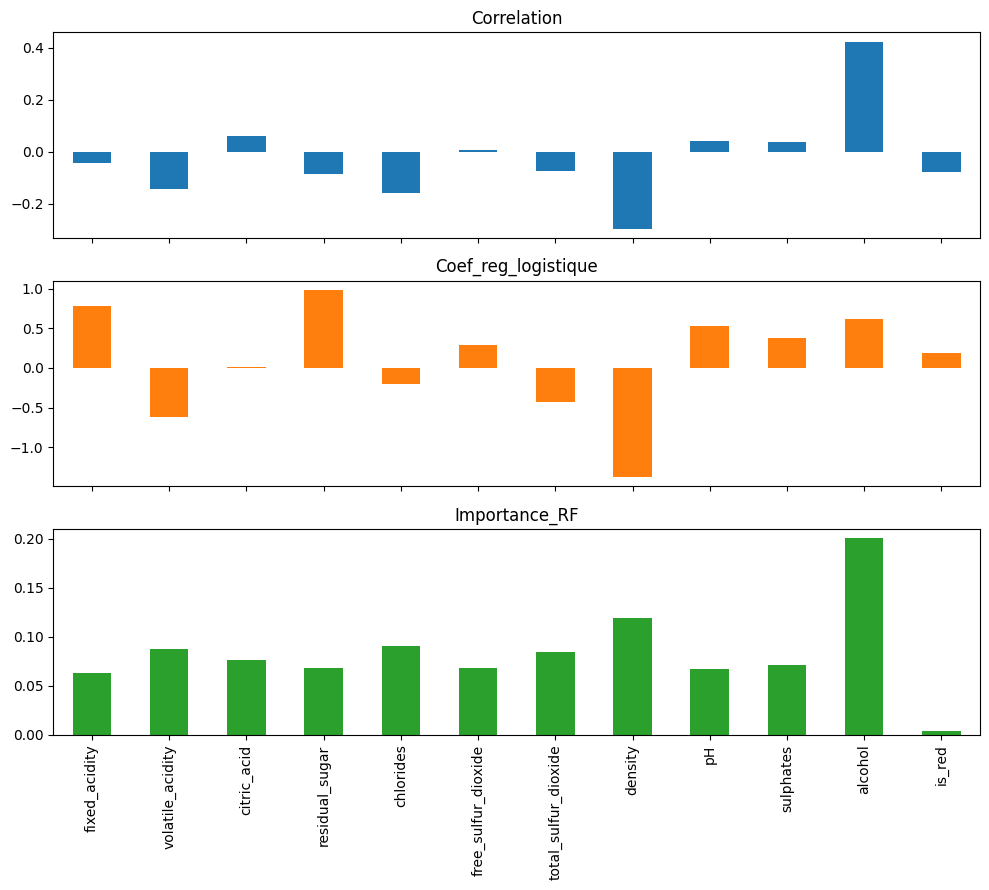

In [ ]:
# Graphiques des trois critères
selection.plot(kind='bar', subplots=True, figsize=(10, 9), legend=False)
plt.tight_layout()
plt.show()

Les trois critères s'accordent sur le haut du classement : alcohol est la variable la plus importante (corrélation de 0,42, coefficient de +0,62, importance de 0,20), suivie de density (corrélation de -0,30, coefficient de -1,37). Viennent ensuite chlorides et volatile_acidity, qui jouent négativement. À l'inverse, is_red a une importance quasi nulle (0,003) et free_sulfur_dioxide une corrélation presque nulle (0,005). Les coefficients de la régression logistique sont élevés pour residual_sugar (+0,98) et fixed_acidity (+0,78) alors que leur corrélation avec la cible est faible : c'est un effet de la multicolinéarité avec density, donc ces coefficients sont à interpréter avec prudence. Nous testons maintenant si garder seulement les meilleures variables, ou utiliser l'ACP, améliore réellement les modèles.

Justification du choix des modèles

- Régression logistique : modèle linéaire, simple et interprétable (les coefficients montrent l'effet de chaque variable). Elle sert de référence. Elle est sensible à la multicolinéarité et à l'échelle des variables.
- k-NN : modèle non linéaire qui ne fait aucune hypothèse sur la distribution des données. Il repose sur des distances, donc il est sensible à l'échelle des variables et aux valeurs aberrantes.
- Arbre de décision : modèle non linéaire, qui n'a pas besoin de mise à l'échelle et qui est peu gêné par les valeurs aberrantes. Il a tendance à sur-apprendre (variance élevée).
- Naive Bayes : modèle probabiliste très rapide, qui suppose des variables indépendantes et gaussiennes. Ces deux hypothèses sont mal respectées ici (corrélations fortes, distributions asymétriques).
- SVM : avec un noyau RBF, il sépare des classes non linéaires et gère bien le bruit grâce au paramètre C. Il est sensible à l'échelle des variables.

Le jeu de données est déséquilibré (environ 20 % de bons vins). On utilise donc class_weight='balanced' quand le modèle le permet, et on juge les modèles surtout sur le F1-score de la classe "bon vin" et sur l'AUC, pas sur l'accuracy seule.

Définition des cinq modèles et de la validation croisée (5 plis). Chaque modèle sera placé dans un Pipeline avec son scaler : ainsi le scaler est appris seulement sur les données d'entraînement de chaque pli.

In [ ]:
modeles = {
    'Régression logistique': LogisticRegression(class_weight='balanced', max_iter=1000),
    'k-NN': KNeighborsClassifier(),
    'Arbre de décision': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Naive Bayes': GaussianNB(),
    'SVM': SVC(class_weight='balanced', random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Comparaison du RobustScaler et du StandardScaler en validation croisée, comme annoncé plus haut (F1-score moyen sur les 5 plis).

In [ ]:
resultats = []
for nom, modele in modeles.items():
    pipe_robust = Pipeline([('scaler', RobustScaler()), ('model', modele)])
    pipe_standard = Pipeline([('scaler', StandardScaler()), ('model', modele)])

    f1_robust = cross_val_score(pipe_robust, X_train, y_train, cv=cv, scoring='f1').mean()
    f1_standard = cross_val_score(pipe_standard, X_train, y_train, cv=cv, scoring='f1').mean()
    resultats.append([nom, f1_robust, f1_standard])

print(pd.DataFrame(resultats, columns=['Modèle', 'F1 RobustScaler', 'F1 StandardScaler']).round(3))

                  Modèle  F1 RobustScaler  F1 StandardScaler
0  Régression logistique            0.530              0.532
1                   k-NN            0.471              0.477
2      Arbre de décision            0.430              0.431
3            Naive Bayes            0.494              0.494
4                    SVM            0.549              0.545


Les écarts entre les deux scalers sont négligeables (au plus 0,006 de F1). Le RobustScaler n'apporte donc pas de gain mesurable par rapport au StandardScaler : il reste justifié en théorie à cause des valeurs aberrantes, mais il ne faut pas lui attribuer d'amélioration. Comme attendu, Naive Bayes et l'arbre de décision, insensibles à l'échelle des variables, donnent des résultats quasi identiques. Nous conservons le RobustScaler.

Comparaison de trois jeux de variables avec les hyperparamètres par défaut : toutes les variables, les 8 variables les plus importantes selon le Random Forest (choisies sur le train uniquement) et l'ACP qui garde 90 % de la variance (F1-score moyen en validation croisée).

In [ ]:
# Les 8 variables les plus importantes selon le Random Forest
meilleures_variables = selection['Importance_RF'].sort_values(ascending=False).head(8).index
print("Variables retenues :", list(meilleures_variables))

resultats = []
for nom, modele in modeles.items():
    pipe_toutes = Pipeline([('scaler', RobustScaler()), ('model', modele)])
    pipe_acp = Pipeline([('scaler', RobustScaler()), ('acp', PCA(n_components=0.90)), ('model', modele)])

    f1_toutes = cross_val_score(pipe_toutes, X_train, y_train, cv=cv, scoring='f1').mean()
    f1_selection = cross_val_score(pipe_toutes, X_train[meilleures_variables], y_train, cv=cv, scoring='f1').mean()
    f1_acp = cross_val_score(pipe_acp, X_train, y_train, cv=cv, scoring='f1').mean()
    resultats.append([nom, f1_toutes, f1_selection, f1_acp])

print(pd.DataFrame(resultats, columns=['Modèle', 'Toutes les variables', 'Sélection RF (8)', 'ACP (90 %)']).round(3))

Variables retenues : ['alcohol', 'density', 'chlorides', 'volatile_acidity', 'total_sulfur_dioxide', 'citric_acid', 'sulphates', 'residual_sugar']
                  Modèle  Toutes les variables  Sélection RF (8)  ACP (90 %)
0  Régression logistique                 0.530             0.535       0.492
1                   k-NN                 0.471             0.436       0.411
2      Arbre de décision                 0.430             0.415       0.384
3            Naive Bayes                 0.494             0.503       0.392
4                    SVM                 0.549             0.527       0.508


Garder toutes les variables est la meilleure option pour le k-NN, l'arbre de décision et le SVM. La sélection de 8 variables est très légèrement meilleure pour la régression logistique (0,535 contre 0,531) et Naive Bayes (0,503 contre 0,494), les deux modèles les plus gênés par la redondance entre variables, mais l'écart reste faible. L'ACP est la moins bonne option pour les cinq modèles (par exemple, Naive Bayes passe de 0,494 à 0,392 et le k-NN de 0,471 à 0,411) : elle supprime de l'information utile, et la multicolinéarité observée n'est pas assez gênante pour justifier une réduction de dimension. Même les variables peu corrélées à la cible aident les modèles non linéaires (le SVM perd 0,022 de F1 avec 8 variables seulement). Pour la suite, nous gardons toutes les variables.

Évaluation des cinq modèles avec leurs hyperparamètres par défaut : on entraîne sur le train, puis on évalue sur le test.

In [ ]:
def score_modele(modele, X_data):
    """Score ut
    ilisé pour l'AUC et la courbe ROC (le SVM n'a pas predict_proba par défaut, on utilise decision_function)."""
    if hasattr(modele, 'predict_proba'):
        return modele.predict_proba(X_data)[:, 1]
    return modele.decision_function(X_data)

def evaluer(modele):
    """Calcule les métriques d'un modèle déjà entraîné, sur le jeu de test."""
    y_pred = modele.predict(X_test)
    return {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Précision': precision_score(y_test, y_pred),
        'Rappel': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, score_modele(modele, X_test)),
    }

modeles_base = {}
resultats_base = {}
for nom, modele in modeles.items():
    pipe = Pipeline([('scaler', RobustScaler()), ('model', modele)])
    pipe.fit(X_train, y_train)
    modeles_base[nom] = pipe
    resultats_base[nom] = evaluer(pipe)

resultats_base = pd.DataFrame(resultats_base).T.round(3)
print(resultats_base)

                       Accuracy  Précision  Rappel     F1    AUC
Régression logistique     0.730      0.394   0.782  0.524  0.817
k-NN                      0.844      0.627   0.441  0.517  0.820
Arbre de décision         0.801      0.475   0.470  0.473  0.674
Naive Bayes               0.733      0.382   0.653  0.482  0.759
SVM                       0.738      0.407   0.832  0.546  0.852


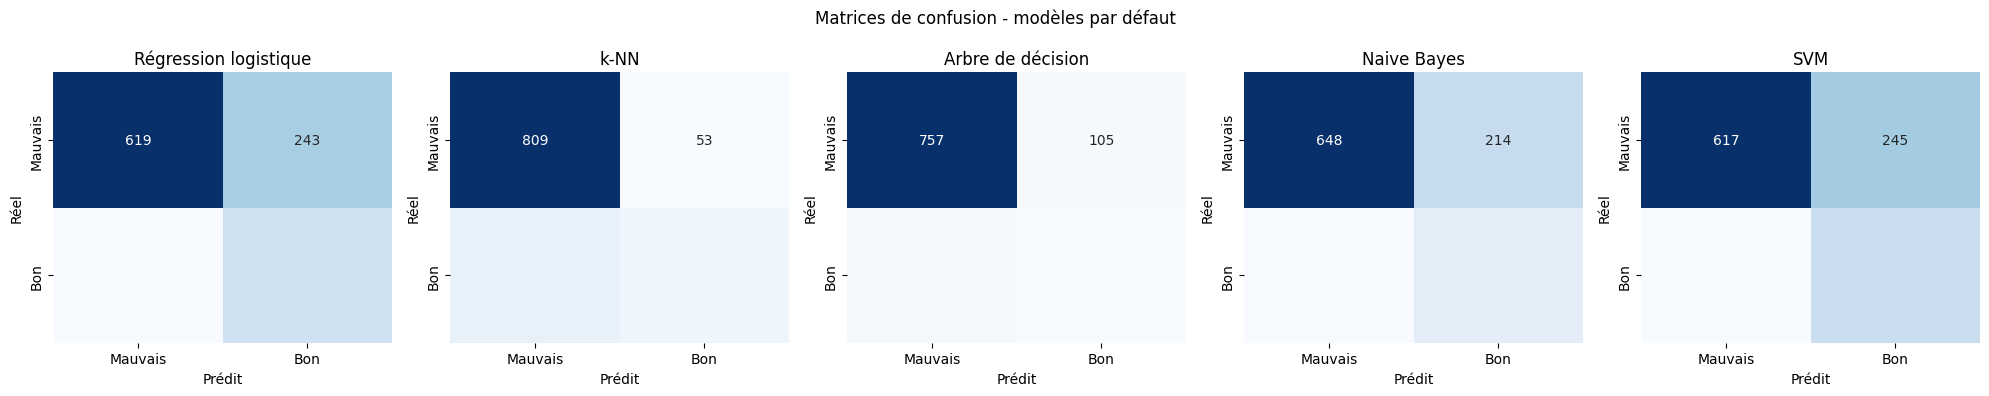

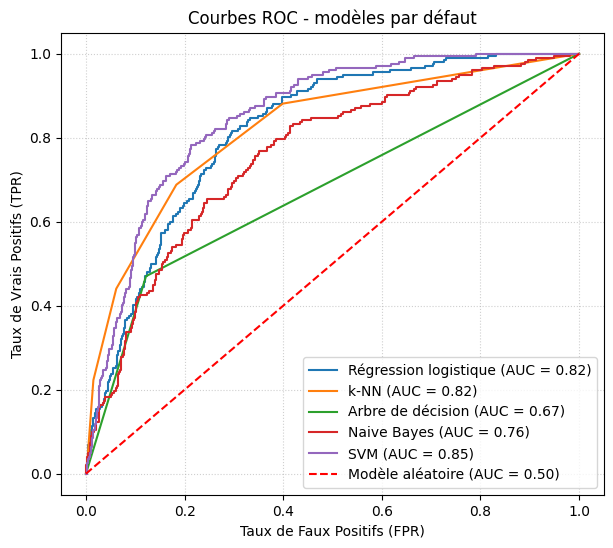

In [ ]:
def afficher_graphiques(dict_modeles, titre):
    # Matrices de confusion
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, (nom, m) in zip(axes, dict_modeles.items()):
        cm = confusion_matrix(y_test, m.predict(X_test))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    xticklabels=['Mauvais', 'Bon'], yticklabels=['Mauvais', 'Bon'])
        ax.set_title(nom)
        ax.set_xlabel('Prédit')
        ax.set_ylabel('Réel')
    plt.suptitle("Matrices de confusion - " + titre)
    plt.tight_layout()
    plt.show()

    # Courbes ROC
    plt.figure(figsize=(7, 6))
    for nom, m in dict_modeles.items():
        scores = score_modele(m, X_test)
        fpr, tpr, _ = roc_curve(y_test, scores)
        auc = roc_auc_score(y_test, scores)
        plt.plot(fpr, tpr, label=f"{nom} (AUC = {auc:.2f})")
    plt.plot([0, 1], [0, 1], 'r--', label="Modèle aléatoire (AUC = 0.50)")
    plt.xlabel("Taux de Faux Positifs (FPR)")
    plt.ylabel("Taux de Vrais Positifs (TPR)")
    plt.title("Courbes ROC - " + titre)
    plt.legend(loc=4)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.show()

afficher_graphiques(modeles_base, "modèles par défaut")

Sur ce jeu de test, un modèle qui prédirait toujours "mauvais vin" aurait déjà 81 % d'accuracy, donc l'accuracy seule est trompeuse. Le k-NN (0,844) et l'arbre de décision (0,801) ont une bonne accuracy mais un rappel faible (0,441 et 0,470) : ils ratent plus de la moitié des bons vins. Le SVM obtient la meilleure AUC (0,852) et le meilleur F1 (0,546), avec un rappel de 0,832 mais une précision de 0,407 : il détecte presque tous les bons vins, au prix de nombreux faux positifs (effet de class_weight='balanced'). La régression logistique se comporte de façon similaire (rappel de 0,782, précision de 0,394).

Optimisation des hyperparamètres avec validation croisée, en maximisant le F1-score. GridSearch (teste toutes les combinaisons) pour la régression logistique, le k-NN, l'arbre et Naive Bayes. RandomizedSearch (teste seulement 15 combinaisons tirées au hasard) pour le SVM, dont la grille est plus grande.

In [ ]:
# Valeurs d'hyperparamètres à tester pour chaque modèle ('model__' désigne le modèle dans le Pipeline)
grilles = {
    'Régression logistique': {'model__C': [0.001, 0.01, 0.1, 1, 10, 100]},
    'k-NN': {'model__n_neighbors': [3, 5, 7, 11, 15, 21],
             'model__weights': ['uniform', 'distance'],
             'model__p': [1, 2]},
    'Arbre de décision': {'model__max_depth': [3, 5, 7, 10, None],
                          'model__min_samples_leaf': [1, 5, 10, 20],
                          'model__criterion': ['gini', 'entropy']},
    'Naive Bayes': {'model__var_smoothing': [1e-11, 1e-9, 1e-7, 1e-5]},
    'SVM': {'model__C': [0.1, 0.5, 1, 2, 5, 10],
            'model__gamma': [0.01, 0.05, 0.1, 0.2, 0.5, 1]},
}

recherches = {}
for nom, modele in modeles.items():
    pipe = Pipeline([('scaler', RobustScaler()), ('model', modele)])

    if nom == 'SVM':
        recherche = RandomizedSearchCV(pipe, grilles[nom], n_iter=15, cv=cv,
                                       scoring='f1', random_state=42, n_jobs=-1)
    else:
        recherche = GridSearchCV(pipe, grilles[nom], cv=cv, scoring='f1', n_jobs=-1)

    recherche.fit(X_train, y_train)
    recherches[nom] = recherche
    print(nom, "| meilleur F1 (CV) =", round(recherche.best_score_, 3))
    print("   meilleurs paramètres :", recherche.best_params_)

Régression logistique | meilleur F1 (CV) = 0.537
   meilleurs paramètres : {'model__C': 0.01}
k-NN | meilleur F1 (CV) = 0.496
   meilleurs paramètres : {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
Arbre de décision | meilleur F1 (CV) = 0.515
   meilleurs paramètres : {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 20}
Naive Bayes | meilleur F1 (CV) = 0.494
   meilleurs paramètres : {'model__var_smoothing': 1e-11}
SVM | meilleur F1 (CV) = 0.547
   meilleurs paramètres : {'model__gamma': 0.2, 'model__C': 0.5}


L'optimisation apporte des gains limités. Le k-NN gagne 0,025 de F1 (5 voisins, distance de Manhattan, poids par distance). L'arbre de décision gagne 0,015 de F1 et surtout 0,117 d'AUC (de 0,674 à 0,791) grâce à une forte régularisation (profondeur 3, au moins 20 échantillons par feuille). La régression logistique choisit une très forte régularisation (C = 0,01) sans amélioration, et Naive Bayes ne change pas. Le SVM garde le même F1 sur le test (0,546 puis 0,545), mais avec C = 0,5 et gamma = 0,2 son modèle est plus simple et colle moins au train. Les modèles par défaut étaient donc déjà proches de leur optimum : la limite vient plutôt des données (classes déséquilibrées, variables peu discriminantes) que du réglage.

Évaluation des modèles optimisés sur le jeu de test, et comparaison avec les modèles par défaut.

In [ ]:
modeles_opt = {}
resultats_opt = {}
for nom, recherche in recherches.items():
    modeles_opt[nom] = recherche.best_estimator_      # meilleur modèle trouvé, déjà entraîné
    resultats_opt[nom] = evaluer(recherche.best_estimator_)

resultats_opt = pd.DataFrame(resultats_opt).T.round(3)
print("Modèles optimisés (test) :")
print(resultats_opt)

# Comparaison avant / après optimisation
comparaison = pd.DataFrame({
    'F1 avant': resultats_base['F1'],
    'F1 après': resultats_opt['F1'],
    'AUC avant': resultats_base['AUC'],
    'AUC après': resultats_opt['AUC'],
})
print()
print("Avant / après optimisation (test) :")
print(comparaison)

Modèles optimisés (test) :
                       Accuracy  Précision  Rappel     F1    AUC
Régression logistique     0.725      0.389   0.792  0.522  0.815
k-NN                      0.846      0.622   0.480  0.542  0.829
Arbre de décision         0.709      0.366   0.733  0.488  0.791
Naive Bayes               0.733      0.382   0.653  0.482  0.759
SVM                       0.738      0.406   0.827  0.545  0.853

Avant / après optimisation (test) :
                       F1 avant  F1 après  AUC avant  AUC après
Régression logistique     0.524     0.522      0.817      0.815
k-NN                      0.517     0.542      0.820      0.829
Arbre de décision         0.473     0.488      0.674      0.791
Naive Bayes               0.482     0.482      0.759      0.759
SVM                       0.546     0.545      0.852      0.853


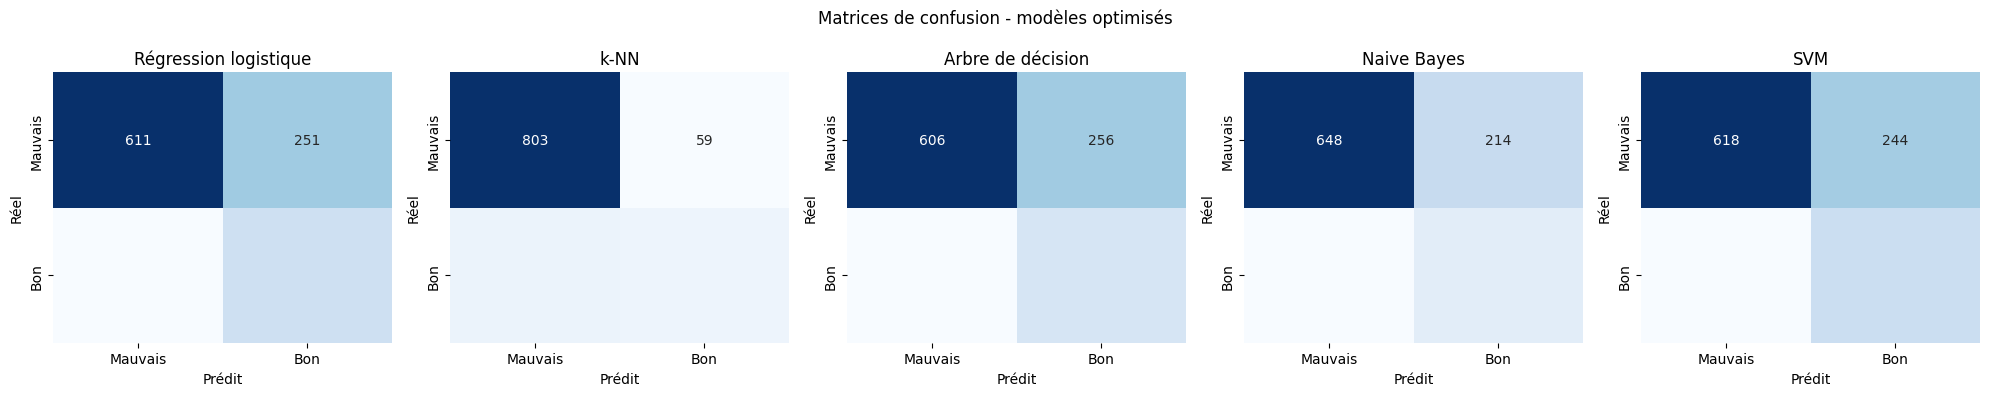

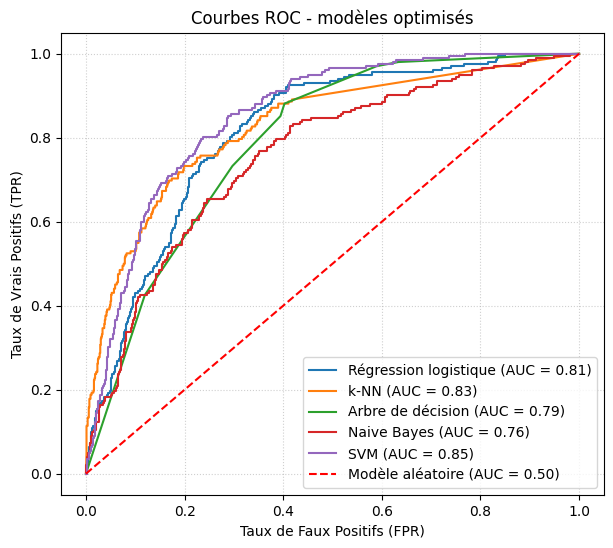

              precision    recall  f1-score   support

     Mauvais       0.95      0.72      0.82       862
         Bon       0.41      0.83      0.54       202

    accuracy                           0.74      1064
   macro avg       0.68      0.77      0.68      1064
weighted avg       0.84      0.74      0.76      1064



In [ ]:
afficher_graphiques(modeles_opt, "modèles optimisés")

# Rapport détaillé du meilleur modèle (SVM optimisé)
print(classification_report(y_test, modeles_opt['SVM'].predict(X_test), target_names=['Mauvais', 'Bon']))

Après optimisation, le SVM reste le meilleur modèle en AUC (0,853) et en F1 (0,545), presque à égalité avec le k-NN (0,542). Le k-NN a la meilleure précision (0,622) et la meilleure accuracy (0,846) mais rate la moitié des bons vins (rappel de 0,480). Le choix dépend donc du coût de l'erreur : pour détecter un maximum de bons vins, le SVM ou la régression logistique (rappel supérieur à 0,79) conviennent mieux ; pour éviter les fausses alertes, le k-NN est préférable. Les courbes ROC confirment le classement SVM > k-NN > régression logistique > arbre > Naive Bayes.

Compromis biais / variance : on compare le F1 sur le train, en validation croisée et sur le test. Un gros écart entre le train et la validation croisée signale du sur-apprentissage (variance élevée). Des scores faibles partout signalent du sous-apprentissage (biais élevé).

                       F1 train  F1 validation croisée  F1 test  \
Modèle                                                            
Régression logistique     0.536                  0.537    0.522   
k-NN                      1.000                  0.496    0.542   
Arbre de décision         0.525                  0.515    0.488   
Naive Bayes               0.496                  0.494    0.482   
SVM                       0.583                  0.547    0.545   

                       Écart train - CV  
Modèle                                   
Régression logistique            -0.000  
k-NN                              0.504  
Arbre de décision                 0.010  
Naive Bayes                       0.002  
SVM                               0.037  


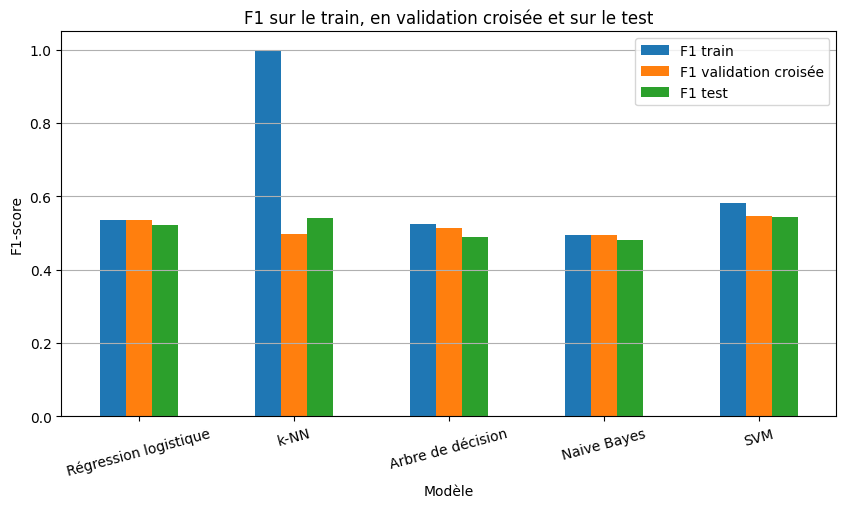

In [ ]:
lignes = []
for nom, m in modeles_opt.items():
    f1_train = f1_score(y_train, m.predict(X_train))
    f1_cv = recherches[nom].best_score_
    f1_test = f1_score(y_test, m.predict(X_test))
    lignes.append([nom, f1_train, f1_cv, f1_test])

biais_variance = pd.DataFrame(lignes, columns=['Modèle', 'F1 train', 'F1 validation croisée', 'F1 test'])
biais_variance = biais_variance.set_index('Modèle')
biais_variance['Écart train - CV'] = biais_variance['F1 train'] - biais_variance['F1 validation croisée']
print(biais_variance.round(3))

biais_variance[['F1 train', 'F1 validation croisée', 'F1 test']].plot(kind='bar', figsize=(10, 5), rot=15)
plt.ylabel('F1-score')
plt.title('F1 sur le train, en validation croisée et sur le test')
plt.grid(axis='y')
plt.show()

La régression logistique et Naive Bayes ont des scores quasi identiques sur le train, en validation croisée et sur le test (autour de 0,5) : biais élevé, sous-apprentissage. Le k-NN a un F1 de 1,0 sur le train contre 0,496 en validation croisée : variance très élevée, car les poids par distance lui font mémoriser le train. L'arbre optimisé a un écart faible (0,010) mais un score moyen : sa forte régularisation le fait basculer vers le biais. Le SVM offre le meilleur compromis : le F1 en validation croisée le plus élevé (0,547), un faible écart avec le train (0,037) et un score de test cohérent (0,545).

Conclusion

Le SVM à noyau RBF (RobustScaler, class_weight='balanced', C = 0,5 et gamma = 0,2) est le modèle retenu : il obtient la meilleure AUC (0,853) et le meilleur F1 (0,545) sur le jeu de test, avec un rappel de 0,827 sur les bons vins et un bon compromis biais/variance.

Les performances restent modestes (F1 d'environ 0,55 sur la classe "bon vin"). Plusieurs raisons l'expliquent : la note est en partie subjective (dégustation) et ne se déduit pas complètement de mesures physico-chimiques, les bons vins ne représentent que 19 % des données, et les variables ont des liens linéaires faibles avec la cible.

Pistes d'amélioration : ajuster le seuil de décision selon l'objectif (précision ou rappel), tester un rééchantillonnage (SMOTE), appliquer une transformation logarithmique aux variables très asymétriques, et comparer avec des modèles d'ensemble (forêt aléatoire, gradient boosting).